In [ ]:
!pip install -q torch-geometric

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.datasets import Planetoid
from torch_geometric.nn import GCNConv
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

torch.manual_seed(42)
np.random.seed(42)

dataset = Planetoid(root='/tmp/Cora', name='Cora')
data = dataset[0]
y_np = data.y.numpy()

In [ ]:
#обычный автоэнкодер, то есть без графа
class BaselineAE(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(in_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, out_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(out_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, in_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

    def encode(self, x):
        return self.encoder(x)

#графовый автоэнкодер, то есть с использованием графа на обучении, то есть имеется граф и смотрим, как он нам поможет дальше
class GAE(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.conv1 = GCNConv(in_dim, hidden_dim)#пользуемся именно им, поскольку он использует как раз таки наш Message Passing: https://deepwiki.com/pyg-team/pytorch_geometric/4-message-passing-framework#1
        self.conv2 = GCNConv(hidden_dim, out_dim)#и собственно как раз посмотрим как Message Passing помогает тут
        self.decoder = nn.Sequential(
            nn.Linear(out_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, in_dim)
        )

    def forward(self, x, edge_index):
        h = F.relu(self.conv1(x, edge_index))
        z = self.conv2(h, edge_index)
        return self.decoder(z), z

    def encode(self, x, edge_index):
        h = F.relu(self.conv1(x, edge_index))
        return self.conv2(h, edge_index)

In [ ]:
def train_ae(model, is_graph=False, epochs=300):
    opt = torch.optim.Adam(model.parameters(), lr=0.01)
    for _ in range(epochs):
        model.train()
        opt.zero_grad()
        if is_graph:#далее data.x-признаки статей, а вот data.edge_index это связи графа
            recon, _ = model(data.x, data.edge_index)#тут он берет граф помимо признаков, на случай если мы хотим получить вход на следующее обучение с использованием графа
        else:
            recon, _ = model(data.x)
        loss = F.mse_loss(recon, data.x)
        loss.backward()
        opt.step()
    return model

In [ ]:
import time

#в первой граф не используется, а во второй имеется граф

start = time.time()
gae_model = train_ae(GAE(dataset.num_features, 64, 32), is_graph=True)
time_gae = time.time() - start

start = time.time()
baseline_ae = train_ae(BaselineAE(dataset.num_features, 64, 32), is_graph=False)
time_base = time.time() - start

print(f"Baseline AE: {time_base:.1f} сек  GAE: {time_gae:.1f} сек")

Baseline AE: 27.7 сек  GAE: 29.4 сек


In [ ]:
#тут уже на основе по факту полученных признаков с предыдущего проверяем обучение в зависимости от числа примеров на класс (n_per_class)
def evaluate(embeddings, y, n_per_class, seed):
    rng = np.random.RandomState(seed)
    train_mask = np.zeros(len(y), dtype=bool)
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        train_mask[rng.choice(idx, min(n_per_class, len(idx)), replace=False)] = True
    clf = LogisticRegression(max_iter=1000)
    clf.fit(embeddings[train_mask], y[train_mask])#тут как раз на вход подаем в первом случае чисто признаки, а вот во втором с графом
    return clf.score(embeddings[~train_mask], y[~train_mask])

In [ ]:
baseline_ae.eval()
gae_model.eval()

with torch.no_grad():
    emb_base = baseline_ae.encode(data.x).numpy()
    emb_gae = gae_model.encode(data.x, data.edge_index).numpy()

SEEDS = [1, 2, 3, 4, 5]
n_list = [1, 2, 3, 5, 10, 20]#имеет смысл делать совсем малое число примеров на тренировку, так как обычный явно не будет успевать еще доучиваться и в теории тот что с графом будет выигрывать на малых особенно
rows = []
mean_base_list, mean_gae_list, std_base_list, std_gae_list = [], [], [], []

for n in n_list:
    acc_base, acc_gae = [], []
    for s in SEEDS:
        acc_base.append(evaluate(emb_base, y_np, n, s))
        acc_gae.append(evaluate(emb_gae, y_np, n, s))

    mean_b, mean_g = np.mean(acc_base), np.mean(acc_gae)
    std_b, std_g = np.std(acc_base), np.std(acc_gae)
    delta = (mean_g - mean_b) * 100

    mean_base_list.append(mean_b)
    mean_gae_list.append(mean_g)
    std_base_list.append(std_b)
    std_gae_list.append(std_g)

    rows.append({
        "n/class": n,
        "без графа": f"{mean_b:.4f} +- {std_b:.4f}",
        "с графом": f"{mean_g:.4f} +- {std_g:.4f}",
        "Прирост": f"{delta:+.2f}"
    })
    print(rows[-1])

df_res = pd.DataFrame(rows)
print(df_res.to_string(index=False))

{'n/class': 1, 'без графа': '0.2515 +- 0.0345', 'с графом': '0.3919 +- 0.0479', 'Прирост': '+14.05'}
{'n/class': 2, 'без графа': '0.3162 +- 0.0459', 'с графом': '0.4794 +- 0.0388', 'Прирост': '+16.32'}
{'n/class': 3, 'без графа': '0.3582 +- 0.0522', 'с графом': '0.5087 +- 0.0590', 'Прирост': '+15.04'}
{'n/class': 5, 'без графа': '0.4099 +- 0.0589', 'с графом': '0.5607 +- 0.0481', 'Прирост': '+15.08'}
{'n/class': 10, 'без графа': '0.4814 +- 0.0317', 'с графом': '0.6186 +- 0.0211', 'Прирост': '+13.71'}
{'n/class': 20, 'без графа': '0.5418 +- 0.0062', 'с графом': '0.6519 +- 0.0101', 'Прирост': '+11.01'}
 n/class        без графа         с графом Прирост
       1 0.2515 +- 0.0345 0.3919 +- 0.0479  +14.05
       2 0.3162 +- 0.0459 0.4794 +- 0.0388  +16.32
       3 0.3582 +- 0.0522 0.5087 +- 0.0590  +15.04
       5 0.4099 +- 0.0589 0.5607 +- 0.0481  +15.08
      10 0.4814 +- 0.0317 0.6186 +- 0.0211  +13.71
      20 0.5418 +- 0.0062 0.6519 +- 0.0101  +11.01


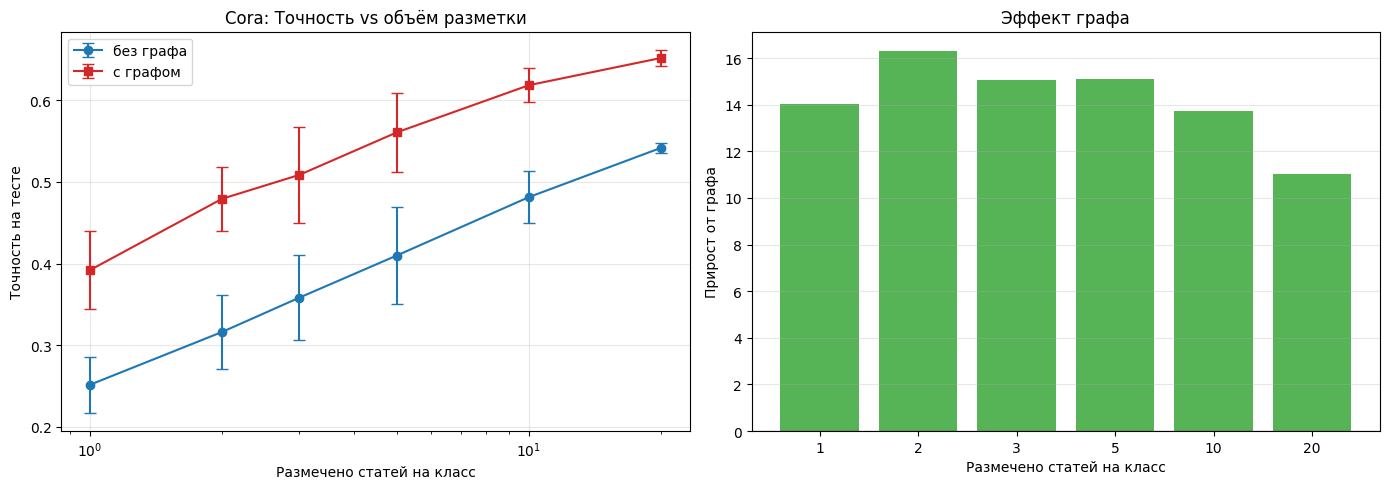

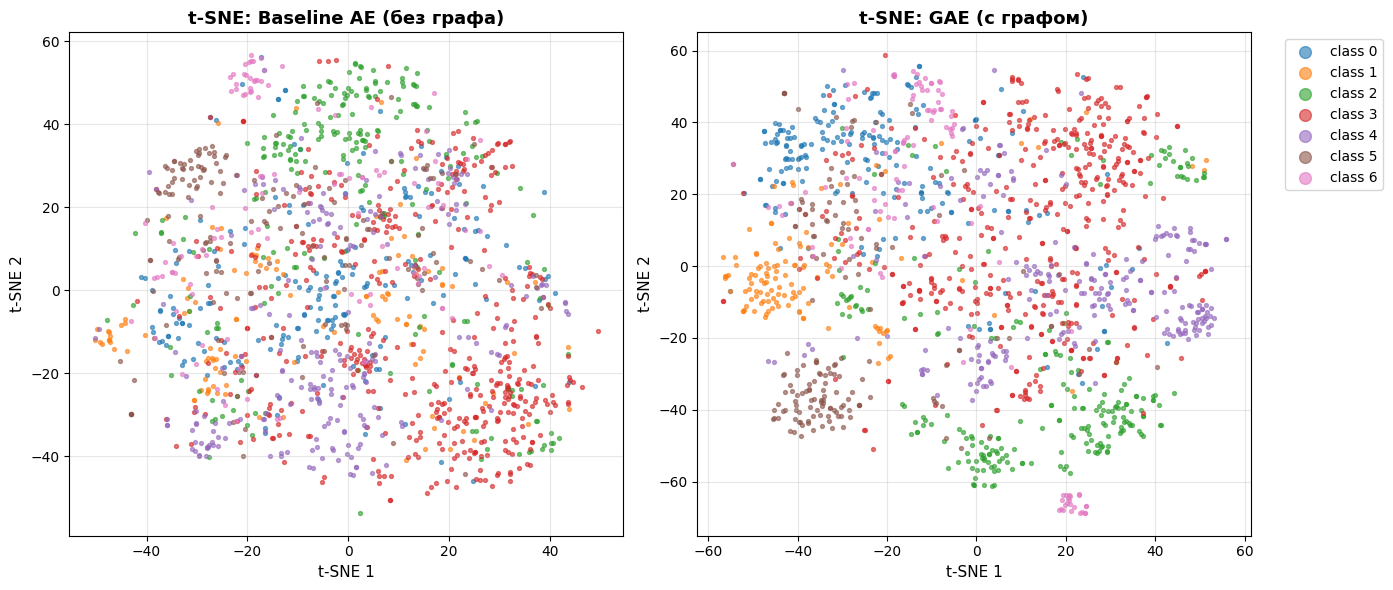

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].errorbar(n_list, mean_base_list, yerr=std_base_list, marker='o', capsize=4, label='без графа', color='#1f77b4')
ax[0].errorbar(n_list, mean_gae_list, yerr=std_gae_list, marker='s', capsize=4, label='с графом', color='#d62728')
ax[0].set_xscale('log')
ax[0].set_xlabel('Размечено статей на класс')
ax[0].set_ylabel('Точность на тесте')
ax[0].set_title('Cora: Точность vs объём разметки')
ax[0].grid(alpha=0.3)
ax[0].legend()

deltas = [(g - b) * 100 for g, b in zip(mean_gae_list, mean_base_list)]
ax[1].bar(range(len(n_list)), deltas, color='#2ca02c', alpha=0.8)
ax[1].axhline(0, color='k', lw=0.8)
ax[1].set_xticks(range(len(n_list)))
ax[1].set_xticklabels(n_list)
ax[1].set_xlabel('Размечено статей на класс')
ax[1].set_ylabel('Прирост от графа')
ax[1].set_title('Эффект графа')
ax[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig("cora_accuracy.png", dpi=200)
plt.show()

rng = np.random.RandomState(0)
sub_idx = rng.choice(data.num_nodes, 1500, replace=False)
y_sub = y_np[sub_idx]

tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=0)
t_base = tsne.fit_transform(emb_base)[sub_idx]
t_gae = tsne.fit_transform(emb_gae)[sub_idx]

palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2']

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, e, title in zip(ax, [t_base, t_gae], ['Baseline AE (без графа)', 'GAE (с графом)']):
    for c in range(7):
        a.scatter(e[y_sub == c, 0], e[y_sub == c, 1], s=8, alpha=0.6, color=palette[c], label=f'class {c}')
    a.set_title(f't-SNE: {title}', fontsize=13, fontweight='bold')
    a.set_xlabel('t-SNE 1', fontsize=11)
    a.set_ylabel('t-SNE 2', fontsize=11)
    a.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', markerscale=3)
plt.tight_layout()
plt.savefig("cora_tsne.png", dpi=200)
plt.show()

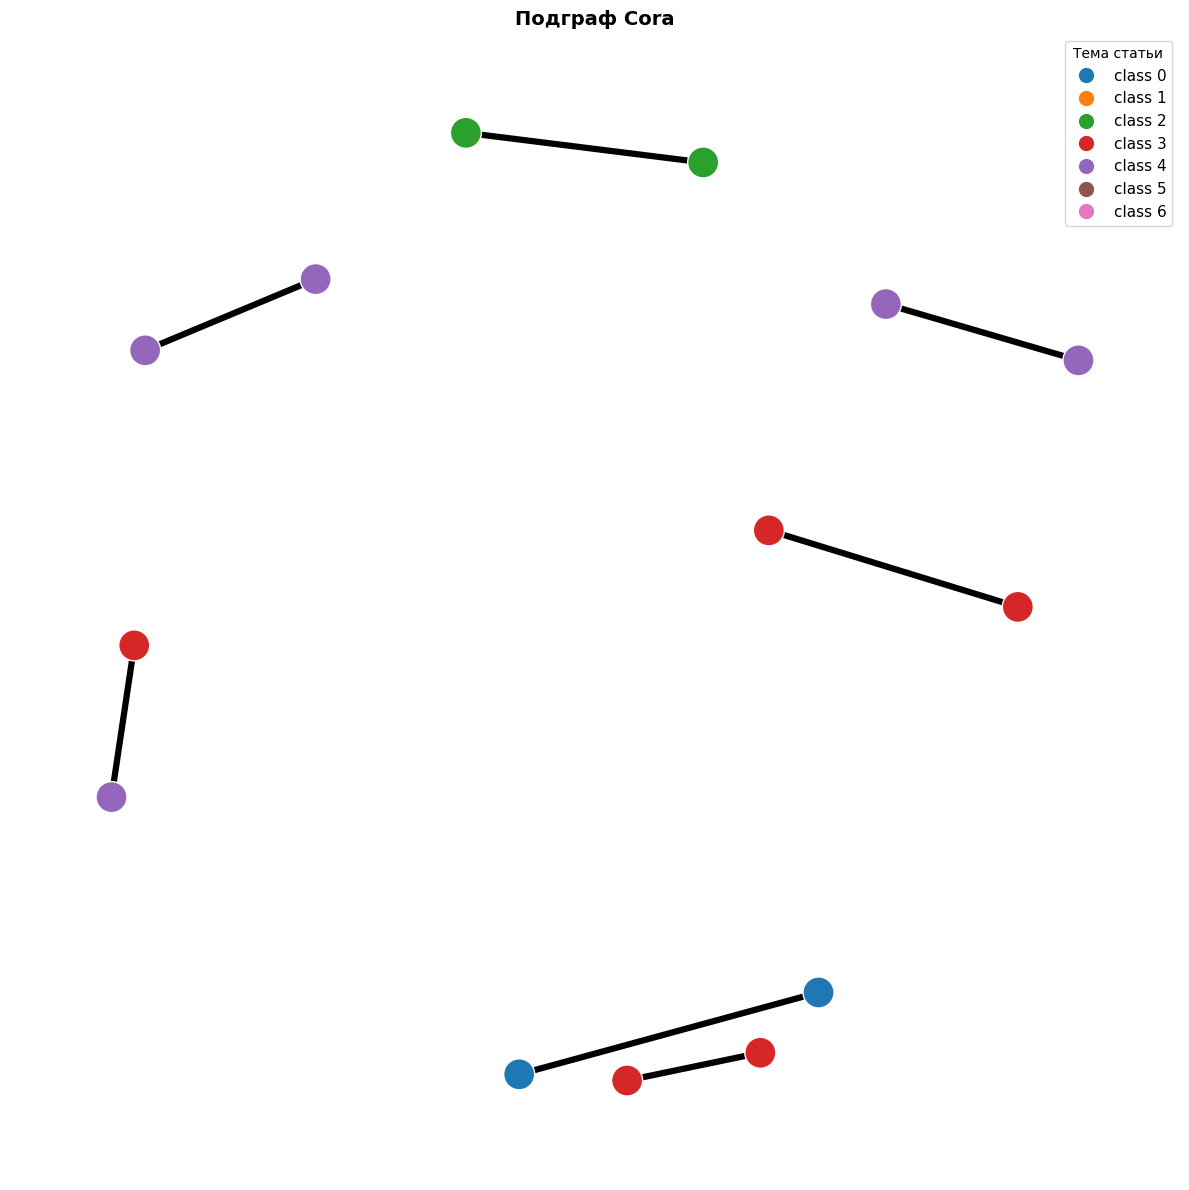

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

edge_index_np = data.edge_index.numpy()
rng_g = np.random.RandomState(42)
sub_nodes = set(rng_g.choice(data.num_nodes, 120, replace=False).tolist())

G = nx.Graph()
for i in range(edge_index_np.shape[1]):
    u, v = int(edge_index_np[0, i]), int(edge_index_np[1, i])
    if u in sub_nodes and v in sub_nodes:
        G.add_edge(u, v)

palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2']
node_colors = [palette[int(y_np[n])] for n in G.nodes()]

plt.figure(figsize=(12, 12))
pos = nx.spring_layout(G, seed=40, k=0.9)
nx.draw_networkx_edges(G, pos, alpha=1.0, width=4.5, edge_color='black')
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=500, linewidths=1.0, edgecolors='white')

from matplotlib.lines import Line2D
legend_elems = [Line2D([0], [0], marker='o', color='w', markersize=12,
                markerfacecolor=palette[c], label=f'class {c}') for c in range(7)]
plt.legend(handles=legend_elems, loc='upper right', fontsize=11, title='Тема статьи')
plt.title('Подграф Cora', fontsize=14, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.savefig("cora_graph.png", dpi=200, bbox_inches='tight')
plt.show()